<a href="https://colab.research.google.com/github/ErrPeppe/OhnomiTools/blob/main/notebooks/02_wgd_vs_ssd_evolution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fase 2 — Identificazione Evolutiva degli Ohno-lncRNA: Modello Intragenico (Ramo A), Filostratigrafia (Ramo B) e Intersezione $A \cap B$

## Introduzione Biologica, Fisica e Metodi Matematici

### 1. Il Problema Biologico: Perché Identificare gli Ohno-lncRNA è Più Complesso che per i miRNA
Nell'analisi dei microRNA umani (Agasso et al., *PLOS Comput. Biol.* 2025), l'identificazione degli ohnologhi intragenici sfrutta il cosiddetto **"modello del passeggero" (*passenger model*)**: si individuano coppie di geni codificanti ohnologhi (WGD) che ospitano entrambi un miRNA con orientamento relativo conservato (`sense`/`antisense`), e si filtrano i falsi positivi tramite database curati (*MirGeneDB*) e *Reciprocal Best Hit* (RBH) di sequenza pesato sulla *seed region*.

Trasferire questo schema ai **lncRNA** introduce due sfide specifiche:
1. **Assenza di una *seed region* e rapida divergenza di sequenza:** a differenza dei miRNA (~22 nt altamente conservati), i lncRNA evolvono rapidamente a livello di sequenza primaria, rendendo fragile un filtraggio puramente basato su RBH a 500 milioni di anni di distanza; d'altro canto, senza un filtro evolutivo, il solo criterio posizionale intragenico rischia di includere inserzioni recentissime (es. trasposoni comparsi nei primati) cadute casualmente negli introni di geni ohnologhi antichi.
2. **Il *blind spot* dei lincRNA intergenici:** mentre moltissimi miRNA sono intronici, una quota sostanziale di lncRNA ancestrali è puramente intergenica (**lincRNA**) e risulterebbe invisibile a un approccio esclusivamente intragenico.

### 2. Architettura a Tre Vie Analitiche
Per combinare il rigore del metodo intragenico con la completezza della filostratigrafia — mantenendo sempre trasparente il contributo di ciascun criterio — questo notebook sviluppa e confronta **tre vie parallele**, che verranno conservate fino alle analisi di rete ed espressione delle Fasi 3 e 4:
* **Via 1 — Ramo A (`Intragenic / Passenger Model`):** estensione diretta di Agasso et al. (2025) sulle coppie di geni host WGD vs SSD (stratificate su SSD antiche pre-*Sarcopterygii* secondo Mottes et al., 2021), imponendo contenimento stretto e conservazione dell'orientamento relativo.
* **Via 2 — Intersezione $A \cap B$ (`Gold Standard`):** coppie intrageniche del Ramo A filtrate lungo una curva progressiva di età filostratigrafica in LncBook v2.0 (dove la filostratigrafia svolge il ruolo di filtro di plausibilità evolutiva che RBH e MirGeneDB svolgevano nei miRNA).
* **Via 3 — Ramo B (`Coorte Filostratigrafica 17. Euteleostomi`):** analisi dell'intera coorte di lncRNA comparsi alla radice dei vertebrati ossei (finestra evolutiva immediatamente successiva alle 1R/2R-WGD), suddivisa per contesto genomico (`intragenic_WGD_host`, `intragenic_other_host`, `intergenic_lincRNA`).

### 3. Formulazione Matematica e Statistica dei Metodi Usati
1. **Intersezione Genomica e Coerenza di Filamento (Ramo A):** un lncRNA $r = (c_r, s_r, e_r, \sigma_r)$ è classificato come intragenico rispetto a un gene host codificante $h = (c_h, s_h, e_h, \sigma_h)$ se $c_r = c_h$ e $s_r \ge s_h \land e_r \le e_h$ (*strict containment*). Il suo orientamento relativo è $\tau(r, h) = \text{sense}$ se $\sigma_r = \sigma_h$, oppure $\text{antisense}$ se $\sigma_r \neq \sigma_h$. Una coppia di host $(h_1, h_2)$ è considerata positiva ($Y = 1$) se esistono almeno due lncRNA distinti $r_1 \subset h_1$ e $r_2 \subset h_2$ tali che $\tau(r_1, h_1) = \tau(r_2, h_2)$.
2. **Test Esatto di Fisher a Livello di Coppia di Host:** per evitare che geni molto lunghi contenenti decine di lncRNA gonfino artificialmente i conteggi, l'unità statistica primaria è la **singola coppia di geni host** ($Y \in \{0, 1\}$), testata con Fisher esatto a due code tra WGD e SSD.
3. **Controllo del Confondente Geometrico di Lunghezza:** poiché i geni WGD tendono a essere più lunghi degli SSD, la maggiore probabilità grezza di ospitare lncRNA potrebbe essere un effetto di taglia (*target-size effect*). Per disaccoppiare taglia genomica e selezione evolutiva applichiamo tre strumenti complementari:
   * **Test U di Mann-Whitney** sulla lunghezza media geometrica della coppia $L_{\text{geom}} = \sqrt{L_1 L_2}$;
   * **Odds Ratio stratificato di Mantel-Haenszel** su $K=8$ quantili di $L_{\text{geom}}$:
     $$\text{OR}_{\text{MH}} = \frac{\sum_{k=1}^{K} \frac{a_k d_k}{N_k}}{\sum_{k=1}^{K} \frac{b_k c_k}{N_k}}$$
     con intervalli di confidenza binomiali di **Wilson al 95%** per ciascun quantile;
   * **Regressione Logistica Multivariata** stimata tramite *Iteratively Reweighted Least Squares* (IRLS):
     $$\operatorname{logit}\!\big(P(Y = 1 \mid \mathbf{x})\big) = \beta_0 + \beta_{\text{WGD}}\,I_{\text{WGD}} + \beta_1 \log_{10}\!\big(\min(L_1, L_2)\big) + \beta_2 \log_{10}\!\big(\max(L_1, L_2)\big)$$
     da cui si ricava l'**Odds Ratio aggiustato per lunghezza** $\text{OR}_{\text{adj}} = e^{\beta_{\text{WGD}}}$ con CI al 95% e test di Wald ($z = \beta_{\text{WGD}} / \text{SE}(\beta_{\text{WGD}})$).

## 1. Setup dell'Ambiente e Caricamento della Libreria

In [1]:
!pip install -q --no-cache-dir git+https://github.com/ErrPeppe/OhnomiTools.git
from ohnomitools import setup_colab
PATHS = setup_colab(update=True, show_status=False)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 2. Ramo A — Intersezione Intragenica WGD vs SSD e Test Esatto di Fisher
Mappatura di tutti i geni lncRNA di LncBook v2.0 contenuti nei geni `protein_coding` di Ensembl e confronto della frazione di coppie host che ospitano una coppia di lncRNA con orientamento coerente tra **WGD** (4.221 coppie) e **SSD** (totali e stratificate su SSD antiche pre-*Sarcopterygii*, secondo Mottes et al. 2021).

In [3]:
import polars as pl
from ohnomitools.evolution import EvolutionAnalyzer

analyzer = EvolutionAnalyzer(paths=PATHS)
out_p2, df_summary = analyzer.run_phase2(
    strict_containment=True,
    require_conserved_rel_strand=True,
    sense_only=False,
    force_rebuild=True,
)

with pl.Config(tbl_cols=12, fmt_str_lengths=55):
    print("=== ARRICCHIMENTO COPPIE HOST WGD vs SSD (Test Esatto di Fisher) ===")
    print(df_summary)

=== ARRICCHIMENTO COPPIE HOST WGD vs SSD (Test Esatto di Fisher) ===
shape: (4, 9)
┌──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ Confront ┆ WGD_host ┆ WGD_con_ ┆ WGD_perc ┆ SSD_host ┆ SSD_con_ ┆ SSD_perc ┆ Odds_Rat ┆ Fisher_p │
│ o        ┆ _pairs_t ┆ coppia_l ┆ entuale  ┆ _pairs_t ┆ coppia_l ┆ entuale  ┆ io       ┆ _value   │
│ ---      ┆ otali    ┆ ncRNA    ┆ ---      ┆ otali    ┆ ncRNA    ┆ ---      ┆ ---      ┆ ---      │
│ str      ┆ ---      ┆ ---      ┆ f64      ┆ ---      ┆ ---      ┆ f64      ┆ f64      ┆ f64      │
│          ┆ i64      ┆ i64      ┆          ┆ i64      ┆ i64      ┆          ┆          ┆          │
╞══════════╪══════════╪══════════╪══════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ WGD vs   ┆ 4221     ┆ 2157     ┆ 51.102   ┆ 127578   ┆ 36896    ┆ 28.92    ┆ 2.5685   ┆ 3.4145e- │
│ SSD_tutt ┆          ┆          ┆          ┆          ┆          ┆          ┆          ┆ 193      │
│ e (sen

## 3. Ispezione delle Coppie Candidate WGD (Round 1R/2R, Orientamento e Coppie 1:1)
Scomposizione delle 19.963 coppie candidate WGD per round di duplicazione e orientamento (`sense` vs `antisense`), con ispezione delle coppie 1:1 pure (un solo lncRNA per ciascun gene host). L'anteprima mette in evidenza la presenza di inserzioni recenti (`1. Homo`, `6. Catarrhini`) dentro host WGD antichi, motivando il filtro filostratigrafico successivo.

In [4]:
df_wgd_lnc = pl.read_parquet(out_p2.wgd_intragenic_pairs)
df_ssd_lnc = pl.read_parquet(out_p2.ssd_intragenic_pairs)

print(f"Coppie candidate lncRNA su host WGD (strand coerente) : {len(df_wgd_lnc):,}")
print(f"  - di cui su coppie host 1:1 pure (1 lncRNA per host): {df_wgd_lnc.filter(pl.col('is_strict_1to1_host')).height:,}")
print(f"  - coppie di host WGD uniche coinvolte               : {df_wgd_lnc['pair_key'].n_unique():,}")
print(f"  - geni lncRNA unici coinvolti (WGD)                 : {pl.concat([df_wgd_lnc['lncrna_1'], df_wgd_lnc['lncrna_2']]).n_unique():,}")

print("\nDistribuzione per round WGD e orientamento relativo (WGD):")
print(
    df_wgd_lnc.group_by(["wgd_round", "rel_strand_1"])
    .agg([
        pl.len().alias("n_coppie_lncRNA"),
        pl.col("pair_key").n_unique().alias("n_coppie_host_WGD"),
    ])
    .sort(["wgd_round", "rel_strand_1"])
)

print("\nPrime 10 coppie candidate 1:1 (host WGD con un solo lncRNA ciascuno):")
display(
    df_wgd_lnc.filter(pl.col("is_strict_1to1_host"))
    .select([
        "gene_name_1", "gene_name_2", "wgd_round", "rel_strand_1",
        "lncrna_1", "lncrna_alias_1", "lncrna_age_1",
        "lncrna_2", "lncrna_alias_2", "lncrna_age_2",
    ])
    .head(10)
)

Coppie candidate lncRNA su host WGD (strand coerente) : 19,963
  - di cui su coppie host 1:1 pure (1 lncRNA per host): 101
  - coppie di host WGD uniche coinvolte               : 2,157
  - geni lncRNA unici coinvolti (WGD)                 : 10,480

Distribuzione per round WGD e orientamento relativo (WGD):
shape: (12, 4)
┌───────────┬──────────────┬─────────────────┬───────────────────┐
│ wgd_round ┆ rel_strand_1 ┆ n_coppie_lncRNA ┆ n_coppie_host_WGD │
│ ---       ┆ ---          ┆ ---             ┆ ---               │
│ str       ┆ str          ┆ u32             ┆ u32               │
╞═══════════╪══════════════╪═════════════════╪═══════════════════╡
│ both      ┆ antisense    ┆ 6560            ┆ 691               │
│ both      ┆ sense        ┆ 3163            ┆ 556               │
│ htf       ┆ antisense    ┆ 195             ┆ 23                │
│ htf       ┆ sense        ┆ 54              ┆ 13                │
│ r1        ┆ antisense    ┆ 1414            ┆ 164               │
│ …    

gene_name_1,gene_name_2,wgd_round,rel_strand_1,lncrna_1,lncrna_alias_1,lncrna_age_1,lncrna_2,lncrna_alias_2,lncrna_age_2
str,str,str,str,str,str,str,str,str,str
"""STX7""","""STX12""","""unk""","""sense""","""HSALNG0053540""",null,"""16. Tetrapoda""","""HSALNG0002017""",null,"""12. Eutheria"""
"""MARCKS""","""MARCKSL1""","""syn""","""antisense""","""HSALNG0149502""",null,"""13. Theria""","""HSALNG0002314""",null,"""13. Theria"""
"""EPHA7""","""EPHA10""","""syn""","""antisense""","""HSALNG0052011""",null,"""17. Euteleostomi""","""HSALNG0002650""",null,"""12. Eutheria"""
"""FHL5""","""FHL3""","""syn""","""sense""","""HSALNG0052098""",null,"""12. Eutheria""","""HSALNG0002680""",null,"""16. Tetrapoda"""
"""TMED1""","""TMED5""","""syn""","""sense""","""HSALNG0123968""",null,"""16. Tetrapoda""","""HSALNG0142236""",null,"""6. Catarrhini"""
"""HMGCS1""","""HMGCS2""","""unk""","""sense""","""HSALNG0041503""",null,"""17. Euteleostomi""","""HSALNG0006513""",null,"""15. Amniota"""
"""CLK1""","""CLK2""","""both""","""antisense""","""HSALNG0021501""",null,"""1. Homo""","""HSALNG0007490""",null,"""11. Boreoeutheria"""
"""UAP1L1""","""UAP1""","""r1""","""sense""","""HSALNG0075349""",null,"""5. Hominoidea""","""HSALNG0008010""",null,"""12. Eutheria"""
"""CNTN3""","""CNTN2""","""both""","""sense""","""HSALNG0026878""",null,"""14. Mammalia""","""HSALNG0009922""",null,"""16. Tetrapoda"""


## 4. Ramo B — Profilo Filostratigrafico di LncBook v2.0 e "Blind Spot" dei lincRNA
Analisi della distribuzione dei 17 nodi evolutivi (`Age`) nell'intero catalogo LncBook v2.0, confronto tra lncRNA intragenici WGD vs SSD e quantificazione della frazione di lncRNA al nodo `17. Euteleostomi` puramente intergenici (**635 lincRNA su 2.051**, pari al ~31%).

In [5]:
df_phylo = pl.read_parquet(out_p2.lncrna_phylostratigraphy)
df_host_map = pl.read_parquet(out_p2.host_lncrna_map)

# 1. Distribuzione delle età (Age) nell'intero catalogo LncBook v2.0
print("=== DISTRIBUZIONE ETÀ (AGE) IN LNCBOOK v2.0 ===")
with pl.Config(tbl_rows=25):
    print(
        df_phylo.group_by(["age_node_num", "lncrna_age"])
        .len()
        .sort("age_node_num", descending=True)
    )

# 2. Quanti dei lncRNA ospitati in coppie WGD hanno età antica (es. Euteleostomi / pre-Mammalia)?
wgd_lnc_ids = pl.concat([
    df_wgd_lnc.select(pl.col("lncrna_1").alias("lncrna_gene_id")),
    df_wgd_lnc.select(pl.col("lncrna_2").alias("lncrna_gene_id")),
]).unique()

ssd_lnc_ids = pl.concat([
    df_ssd_lnc.select(pl.col("lncrna_1").alias("lncrna_gene_id")),
    df_ssd_lnc.select(pl.col("lncrna_2").alias("lncrna_gene_id")),
]).unique()

print("\n=== CONFRONTO ETÀ EVOLUTIVA: WGD intragenici vs SSD intragenici ===")
print("Top 8 nodi evolutivi nei lncRNA di coppie WGD:")
print(
    wgd_lnc_ids.join(df_phylo, on="lncrna_gene_id", how="left")
    .group_by(["age_node_num", "lncrna_age"])
    .len()
    .sort("len", descending=True)
    .head(8)
)

print("\nTop 8 nodi evolutivi nei lncRNA di coppie SSD:")
print(
    ssd_lnc_ids.join(df_phylo, on="lncrna_gene_id", how="left")
    .group_by(["age_node_num", "lncrna_age"])
    .len()
    .sort("len", descending=True)
    .head(8)
)

# 3. Quanti lncRNA antichi (Euteleostomi) sono intergenici vs intragenici?
eut_all = df_phylo.filter(pl.col("is_euteleostomi"))
eut_intra = eut_all.join(
    df_host_map.select("lncrna_gene_id").unique(), on="lncrna_gene_id", how="semi"
)
print(f"\nTotale lncRNA al nodo Euteleostomi : {len(eut_all):,}")
print(f"  - Intragenici (dentro protein-coding): {len(eut_intra):,}")
print(f"  - Intergenici (lincRNA puri)         : {len(eut_all) - len(eut_intra):,}")

=== DISTRIBUZIONE ETÀ (AGE) IN LNCBOOK v2.0 ===
shape: (17, 3)
┌──────────────┬──────────────────────┬───────┐
│ age_node_num ┆ lncrna_age           ┆ len   │
│ ---          ┆ ---                  ┆ ---   │
│ i32          ┆ str                  ┆ u32   │
╞══════════════╪══════════════════════╪═══════╡
│ 17           ┆ 17. Euteleostomi     ┆ 2051  │
│ 16           ┆ 16. Tetrapoda        ┆ 4269  │
│ 15           ┆ 15. Amniota          ┆ 5181  │
│ 14           ┆ 14. Mammalia         ┆ 4339  │
│ 13           ┆ 13. Theria           ┆ 9783  │
│ 12           ┆ 12. Eutheria         ┆ 32383 │
│ 11           ┆ 11. Boreoeutheria    ┆ 13776 │
│ 10           ┆ 10. Euarchontoglires ┆ 3270  │
│ 9            ┆ 9. Primates          ┆ 601   │
│ 8            ┆ 8. Haplorrhini       ┆ 871   │
│ 7            ┆ 7. Simiiformes       ┆ 3156  │
│ 6            ┆ 6. Catarrhini        ┆ 3290  │
│ 5            ┆ 5. Hominoidea        ┆ 1256  │
│ 4            ┆ 4. Hominidae         ┆ 998   │
│ 3            ┆ 3. Homin

## 5. Controllo Statistico sul Confondente della Lunghezza dei Geni Host

L'analisi della Cella 2 mostra che il **51,1%** delle coppie host WGD ospita una coppia di lncRNA con orientamento coerente contro il **30,6%** delle coppie SSD antiche ($\text{OR}_{\text{grezzo}} = 2{,}37$, $p \approx 2 \times 10^{-162}$).

Tuttavia, è noto in genomica evolutiva che i geni ohnologhi (WGD) possiedono mediamente una **lunghezza genomica (e introni) significativamente maggiore** rispetto ai geni SSD. Un'obiezione fondamentale da verificare è quindi se tale arricchimento sia:
* una **reale firma evolutiva** di ritenzione/co-duplicazione, oppure
* un **artefatto geometrico** dovuto al fatto che geni più lunghi offrono uno "spazio bersaglio" maggiore in cui lncRNA casuali possono cadere per puro caso.

Per rispondere quantitativamente a questa obiezione, la cella seguente applica tre verifiche indipendenti:
1. **Test U di Mann-Whitney** sulla lunghezza media geometrica $\sqrt{L_1 L_2}$ delle coppie WGD rispetto alle SSD antiche.
2. **Stratificazione in 8 bin di lunghezza** (quantili di $\sqrt{L_1 L_2}$) con calcolo dell'**Odds Ratio di Mantel-Haenszel ($\text{OR}_{\text{MH}}$)**, confrontando WGD e SSD *esclusivamente tra coppie della stessa taglia genomica*.
3. **Regressione Logistica Multivariata**:
   $$\operatorname{logit}\big(P(Y=1)\big) = \beta_0 + \beta_{\text{WGD}} \cdot I_{\text{WGD}} + \beta_1 \log_{10}\big(\min(L_1, L_2)\big) + \beta_2 \log_{10}\big(\max(L_1, L_2)\big)$$
   che stima l'**Odds Ratio aggiustato per lunghezza ($\text{OR}_{\text{adj}} = e^{\beta_{\text{WGD}}}$)** e la sua significatività statistica controllando simultaneamente sia la lunghezza del gene più corto (collo di bottiglia) sia di quello più lungo della coppia.

In [2]:
import polars as pl
from ohnomitools.evolution import EvolutionAnalyzer

analyzer = EvolutionAnalyzer(paths=PATHS)
length_res = analyzer.analyze_host_length_confounding(
    use_ancient_ssd=True,
    n_bins=8,
)

print("=== SINTESI CONTROLLO LUNGHEZZA HOST (WGD vs SSD Antiche) ===")
with pl.Config(tbl_cols=15, fmt_str_lengths=40):
    print(length_res["summary"])

print("\n=== DETTAGLIO PER BIN DI LUNGHEZZA MEDIA GEOMETRICA (sqrt(L1 * L2)) ===")
with pl.Config(tbl_rows=10, tbl_cols=15, fmt_str_lengths=30):
    print(
        length_res["bins"].select([
            "Bin", "Range_kb", "WGD_n", "WGD_pct", "SSD_n", "SSD_pct", "Bin_OR", "Bin_p_value"
        ])
    )

=== SINTESI CONTROLLO LUNGHEZZA HOST (WGD vs SSD Antiche) ===
shape: (1, 13)
┌─────┬─────┬─────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ SSD ┆ WGD ┆ SSD ┆ Length ┆ MannW ┆ OR_cr ┆ Fishe ┆ OR_Ma ┆ OR_ad ┆ OR_ad ┆ OR_ad ┆ Logis ┆ Logis │
│ _co ┆ _me ┆ _me ┆ _ratio ┆ hitne ┆ ude_F ┆ r_cru ┆ ntelH ┆ j_len ┆ j_CI9 ┆ j_CI9 ┆ tic_z ┆ tic_p │
│ ntr ┆ dia ┆ dia ┆ _WGD_o ┆ y_len ┆ isher ┆ de_p  ┆ aensz ┆ gth   ┆ 5_low ┆ 5_hig ┆ ---   ┆ _valu │
│ ol_ ┆ n_g ┆ n_g ┆ ver_SS ┆ gth_p ┆ ---   ┆ ---   ┆ el_st ┆ ---   ┆ ---   ┆ h     ┆ f64   ┆ e     │
│ set ┆ eom ┆ eom ┆ D      ┆ ---   ┆ f64   ┆ f64   ┆ ratif ┆ f64   ┆ f64   ┆ ---   ┆       ┆ ---   │
│ --- ┆ _le ┆ _le ┆ ---    ┆ f64   ┆       ┆       ┆ ied   ┆       ┆       ┆ f64   ┆       ┆ f64   │
│ str ┆ n_k ┆ n_k ┆ f64    ┆       ┆       ┆       ┆ ---   ┆       ┆       ┆       ┆       ┆       │
│     ┆ b   ┆ b   ┆        ┆       ┆       ┆       ┆ f64   ┆       ┆       ┆       ┆       ┆       │
│     ┆ --- ┆ 

## 6. Curva di Sensibilità dell'Intersezione $A \cap B$ ed Esportazione delle 3 Vie

Per risolvere il problema delle inserzioni recenti dentro host WGD (emerse nella Cella 3, come `CLK1–CLK2` con un lncRNA `1. Homo`), applichiamo il filtro filostratigrafico di LncBook v2.0 alle coppie intrageniche lungo una **curva di soglie crescenti** (da *Tutte le età* fino a `17. Euteleostomi` stretto e asimmetrico).

Per ogni soglia calcoliamo **sia** l'$\text{OR}_{\text{grezzo}}$ **sia** l'$\text{OR}_{\text{adj}}$ corretto per la lunghezza dei geni host:
* se l'arricchimento *aggiustato per lunghezza* rimane significativo o **cresce** al restringersi verso i nodi più antichi (`15. Amniota` $\to$ `16. Tetrapoda` $\to$ `17. Euteleostomi`), otteniamo la prova più forte che l'Intersezione $A \cap B$ isola veri lncRNA ancestrali co-duplicati con le WGD.

La cella esporta inoltre in `silver/` i dataset ufficiali delle **3 vie analitiche** pronti per la Fase 3 (reti di interazione, *V-motifs*, *Bifans* e modelli nulli di Maslov-Sneppen):
* **Via 1 (`silver/wgd_intragenic_lncrna_pairs.parquet`):** Ramo A puro (continuità diretta con Agasso et al.).
* **Via 2 (`silver/lane2_ab_wgd_pairs.parquet`):** Intersezione $A \cap B$ (*Gold Standard*, entrambi $\ge 15.\,\text{Amniota}$ con flag di tier per `Tetrapoda` ed `Euteleostomi`).
* **Via 3 (`silver/lane3_ramoB_euteleostomi_cohort.parquet`):** Coorte Ramo B (`17. Euteleostomi` completa, con etichetta `intragenic_WGD_host` vs `intragenic_other_host` vs `intergenic_lincRNA`).

In [3]:
df_ab_curve = analyzer.run_ab_sensitivity_curve(
    use_ancient_ssd=True,
    export_three_lanes=True,
)

print("=== CURVA DI SENSIBILITÀ INTERSEZIONE A ∩ B (OR Grezzo vs OR Aggiustato per Lunghezza) ===")
with pl.Config(tbl_rows=10, tbl_cols=15, fmt_str_lengths=45):
    print(
        df_ab_curve.select([
            "Soglia_A_cap_B", "WGD_host_pos", "WGD_pct", "SSD_host_pos", "SSD_pct",
            "OR_crude", "OR_adj_length", "OR_adj_CI95_low", "OR_adj_CI95_high", "Logistic_p"
        ])
    )

# Riepilogo della Via 3 (Ramo B puro) esportata in Silver
df_via3 = pl.read_parquet(PATHS.silver / "lane3_ramoB_euteleostomi_cohort.parquet")
print("\n=== COMPOSIZIONE VIA 3 (Coorte 17. Euteleostomi) ===")
print(df_via3.group_by("genomic_context").len().sort("len", descending=True))

=== CURVA DI SENSIBILITÀ INTERSEZIONE A ∩ B (OR Grezzo vs OR Aggiustato per Lunghezza) ===
shape: (6, 10)
┌─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬────────┐
│ Soglia_ ┆ WGD_hos ┆ WGD_pct ┆ SSD_hos ┆ SSD_pct ┆ OR_crud ┆ OR_adj_ ┆ OR_adj_ ┆ OR_adj_ ┆ Logist │
│ A_cap_B ┆ t_pos   ┆ ---     ┆ t_pos   ┆ ---     ┆ e       ┆ length  ┆ CI95_lo ┆ CI95_hi ┆ ic_p   │
│ ---     ┆ ---     ┆ f64     ┆ ---     ┆ f64     ┆ ---     ┆ ---     ┆ w       ┆ gh      ┆ ---    │
│ str     ┆ i64     ┆         ┆ i64     ┆         ┆ f64     ┆ f64     ┆ ---     ┆ ---     ┆ f64    │
│         ┆         ┆         ┆         ┆         ┆         ┆         ┆ f64     ┆ f64     ┆        │
╞═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪════════╡
│ 1. Ramo ┆ 2157    ┆ 51.102  ┆ 36276   ┆ 30.608  ┆ 2.3692  ┆ 1.2807  ┆ 1.1858  ┆ 1.3833  ┆ 3.0584 │
│ A puro  ┆         ┆         ┆         ┆         ┆         ┆         ┆         ┆     

## 7. Visualizzazione Diagnostica della Fase 2 (Export in `gold/` per il Report)
Generazione della figura a due pannelli salvata automaticamente su Google Drive in `gold/phase2_length_control_and_ab_curve.png` (300 dpi) e `.pdf` (vettoriale per LaTeX):
* **Pannello A:** percentuale di coppie host con coppia lncRNA coerente in funzione della lunghezza media geometrica $\sqrt{L_1 L_2}$ (WGD in rosso vs SSD antiche in blu, barre di errore CI 95% di Wilson).
* **Pannello B:** confronto tra $\text{OR}_{\text{grezzo}}$ e $\text{OR}_{\text{adj}}$ (con CI 95%) lungo le soglie evolutive dell'Intersezione $A \cap B$.

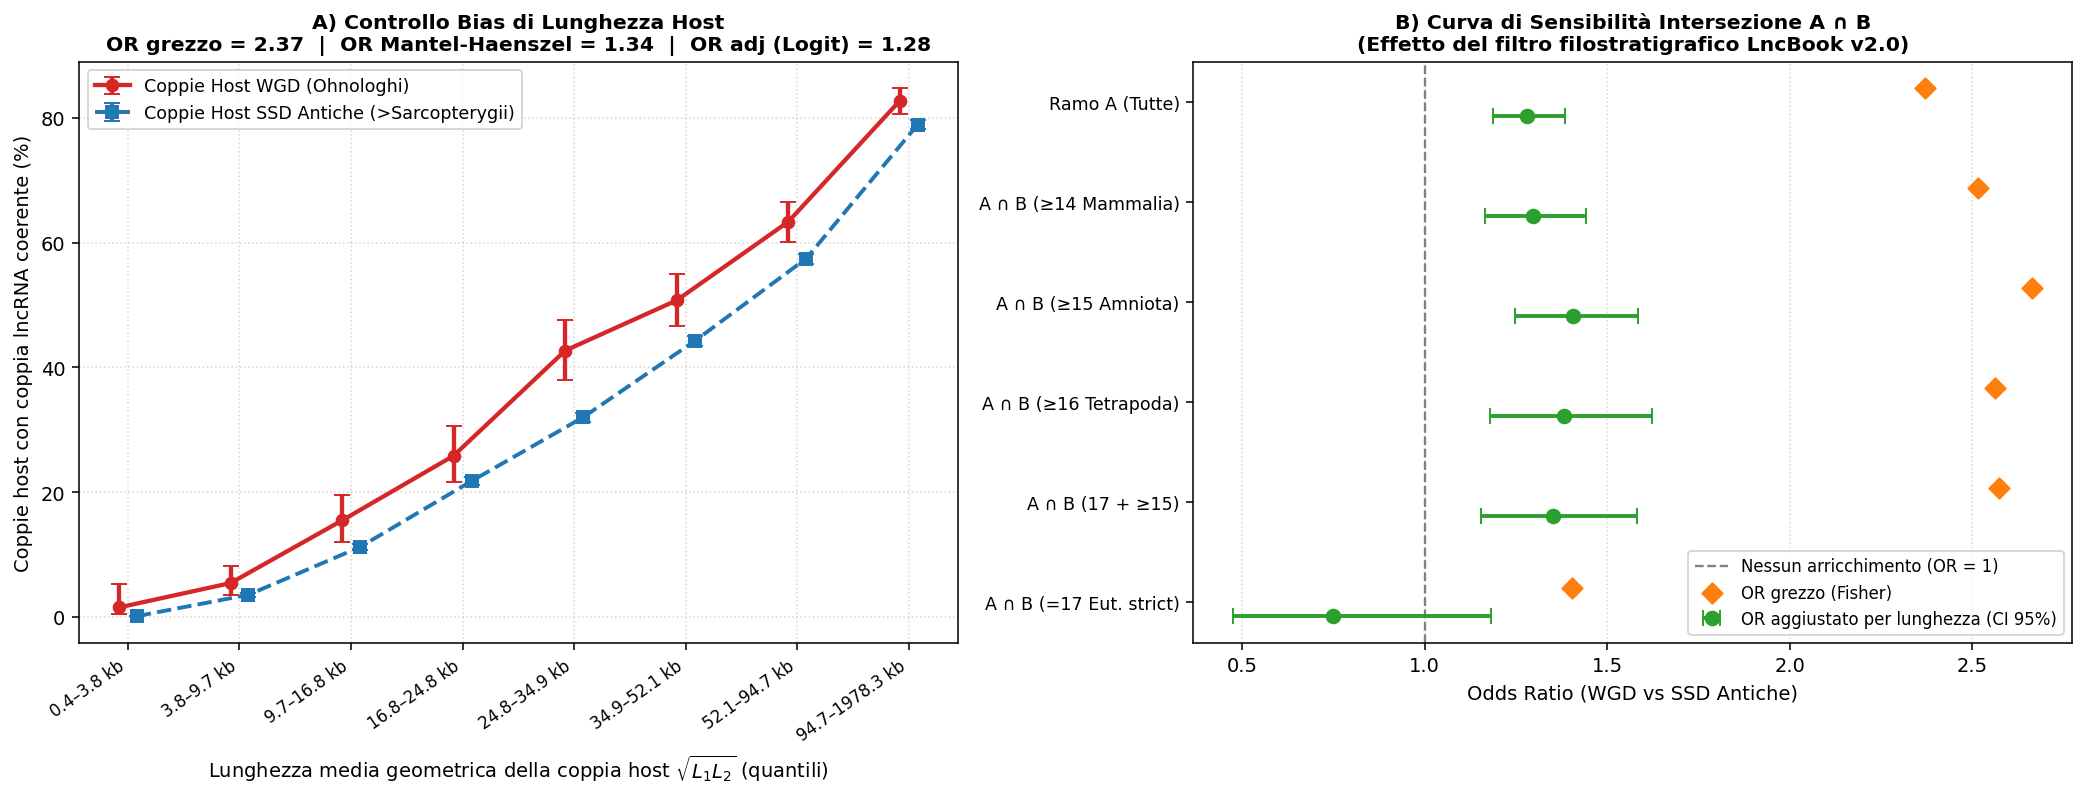

Figure salvate su Google Drive:
 - /content/rclone_drive/gold/phase2_length_control_and_ab_curve.png
 - /content/rclone_drive/gold/phase2_length_control_and_ab_curve.pdf


In [4]:
png_path, pdf_path = analyzer.plot_phase2_diagnostics(
    length_res=length_res,
    df_ab_curve=df_ab_curve,
    save_fig=True,
)
print(f"Figure salvate su Google Drive:\n - {png_path}\n - {pdf_path}")

## 8. Discussione dei Risultati della Fase 2

L'analisi congiunta dei due rami e dei controlli statistici (Celle 2–7) produce quattro evidenze principali:

### 1. Ramo A: Forte Arricchimento Intragenico WGD vs SSD — e Sua Decomposizione
A livello grezzo (Cella 2), il **51,10%** delle coppie host WGD (2.157 su 4.221) ospita una coppia di lncRNA con orientamento relativo coerente, contro il **28,92%** di tutte le SSD (36.896 su 127.578; $\text{OR} = 2{,}57$, $p = 3{,}41 \times 10^{-193}$) e il **30,61%** delle SSD antiche pre-*Sarcopterygii* (36.276 su 118.517; $\text{OR} = 2{,}37$, $p = 1{,}98 \times 10^{-162}$). Il segnale è presente sia sui trascritti `sense` ($\text{OR} = 1{,}96$, $p = 9{,}17 \times 10^{-78}$) sia sugli `antisense` ($\text{OR} = 2{,}29$, $p = 2{,}60 \times 10^{-133}$).

Tuttavia, il controllo della Cella 5 dimostra che **il confondente geometrico di lunghezza era reale e sostanziale**: le coppie host WGD hanno una lunghezza media geometrica mediana di **50,32 kb** contro **24,23 kb** delle SSD antiche (rapporto **$2{,}08\times$**, Mann-Whitney $p = 2{,}31 \times 10^{-296}$). Una volta rimosso l'effetto taglia, l'arricchimento si ridimensiona ma **resta altamente significativo e coerente su tutta la scala genomica**:
* **Mantel-Haenszel stratificato (8 quantili):** $\text{OR}_{\text{MH}} = 1{,}34$, con la curva WGD sistematicamente superiore alla curva SSD in **tutti e 8 i bin di lunghezza** (da $0{,}4\text{–}3{,}8\text{ kb}$ fino a $94{,}7\text{–}1978{,}3\text{ kb}$, Pannello A della figura diagnostica);
* **Regressione logistica multivariata continua:** $\text{OR}_{\text{adj}} = 1{,}28$ (CI 95%: $1{,}19\text{–}1{,}38$, $z = 6{,}30$, **$p = 3{,}06 \times 10^{-10}$**).

In sintesi, circa metà dell'Odds Ratio grezzo è attribuibile alla maggiore estensione genomica degli ohnologhi, mentre la quota residua rappresenta una **reale sovrarappresentazione selettiva** delle coppie di lncRNA intragenici nei geni WGD.

### 2. Limite del Ramo A Puro e Validazione della Curva di Sensibilità $A \cap B$
L'ispezione delle 101 coppie 1:1 pure (Cella 3) rivela che il Ramo A non filtrato include inevitabilmente coppie spuriae generate da inserzioni recenti (es. `CLK1–CLK2`, che accoppia un lncRNA `1. Homo` con un `11. Boreoeutheria`, o `TMED1–TMED5`, che accoppia un `16. Tetrapoda` con un `6. Catarrhini`).

Applicando il filtro filostratigrafico di LncBook v2.0 lungo una curva progressiva (Cella 6, Pannello B), l'**Odds Ratio aggiustato per lunghezza $\text{OR}_{\text{adj}}$ cresce al crescere dell'antichità richiesta**:
* Ramo A puro (tutte le età): $\text{OR}_{\text{adj}} = 1{,}28$ ($p = 3{,}06 \times 10^{-10}$, 2.157 coppie WGD);
* $A \cap B$ ($\ge 14.\,\text{Mammalia}$): $\text{OR}_{\text{adj}} = 1{,}30$ ($p = 2{,}0 \times 10^{-6}$, 495 coppie WGD);
* **$A \cap B$ ($\ge 15.\,\text{Amniota}$ — picco):** **$\text{OR}_{\text{adj}} = 1{,}41$** (CI 95%: $1{,}25\text{–}1{,}58$, **$p = 2{,}13 \times 10^{-8}$**, 368 coppie WGD);
* $A \cap B$ ($\ge 16.\,\text{Tetrapoda}$): $\text{OR}_{\text{adj}} = 1{,}38$ ($p = 7{,}0 \times 10^{-5}$, 185 coppie WGD);
* $A \cap B$ asimmetrico (`17. Euteleostomi` + $\ge 15.\,\text{Amniota}$): $\text{OR}_{\text{adj}} = 1{,}35$ ($p = 1{,}78 \times 10^{-4}$, 192 coppie WGD).

Al contrario, la soglia simmetrica estrema **`17. Euteleostomi` su entrambi i membri** collassa a sole 20 coppie host WGD ($\text{OR}_{\text{adj}} = 0{,}75$, $p = 0{,}213$, non significativo). Questo comportamento ha una chiara interpretazione biologica: poiché LncBook v2.0 inferisce l'età mediante allineamento di sequenza attraverso i vertebrati e i lncRNA divergono molto più rapidamente dei miRNA, dopo 500 milioni di anni è raro che *entrambe* le copie paraloghe conservino simultaneamente una sequenza riconoscibile fino ai pesci ossei; molto più frequentemente una copia rimane rilevabile al nodo `17` mentre la copia sorella scivola al nodo `16` o `15` (come osservato già nella coppia 1:1 `HMGCS1–HMGCS2`). Questo individua nella soglia **$\ge 15.\,\text{Amniota}$** (con sotto-livelli annotati per $\ge 16$ e asimmetrico $17/\ge 15$) il miglior compromesso statistico e biologico per la **Via 2 ($A \cap B$)**.

### 3. Ramo B: Quantificazione del *Blind Spot* Intergenico e Sovrarappresentazione nei Geni WGD
Nell'intero catalogo LncBook v2.0 (95.243 geni classificati su 17 nodi evolutivi), esattamente **2.051 lncRNA** (il 2,15%) risalgono al nodo `17. Euteleostomi`. La loro decomposizione genomica (Cella 6) mostra due risultati complementari:
* **509 su 2.051 (24,8%)** risiedono all'interno dei soli 4.602 geni host WGD (una densità molto più alta rispetto ai 907 distribuiti nei restanti ~15.000 geni `protein_coding`);
* **635 su 2.051 (31,0%)** sono **lincRNA puramente intergenici**, dimostrando quantitativamente che un approccio esclusivamente intragenico perderebbe quasi un terzo dei lncRNA più antichi del genoma umano.

## 9. Conclusioni

La Fase 2 dimostra che l'impronta evolutiva delle duplicazioni dell'intero genoma (1R/2R-WGD) è statisticamente rilevabile anche a livello dei lncRNA umani, e valida la necessità di mantenere **tre vie analitiche complementari**:

1. **Il metodo intragenico (Via 1 — Ramo A) regge il controllo più severo:** anche rimuovendo completamente il bias dovuto alla doppia lunghezza mediana dei geni WGD rispetto agli SSD antichi, le coppie host WGD ospitano coppie di lncRNA con orientamento conservato con probabilità significativamente maggiore ($\text{OR}_{\text{adj}} = 1{,}28$, $p = 3{,}06 \times 10^{-10}$; $\text{OR}_{\text{MH}} = 1{,}34$).
2. **La filostratigrafia potenzia il metodo intragenico (Via 2 — Intersezione $A \cap B$):** rimuovere le inserzioni giovani (`1. Homo`–`13. Theria`) fa **salire** l'Odds Ratio aggiustato fino a **$\text{OR}_{\text{adj}} = 1{,}41$** ($p = 2{,}13 \times 10^{-8}$) alla soglia $\ge 15.\,\text{Amniota}$, offrendo per i lncRNA l'equivalente rigoroso del filtro RBH/MirGeneDB usato sui miRNA.
3. **La coorte filostratigrafica completa (Via 3 — Ramo B) preserva i lincRNA intergenici:** isola i **635 lincRNA** al nodo `17. Euteleostomi` affiancandoli ai 509 intragenici in host WGD e ai 907 in altri host codificanti, permettendo di testare nelle fasi successive se eventuali proprietà topologiche o espressive dipendano dalla residenza in un host ohnologo oppure dall'età evolutiva in sé.

Tutti gli output analitici e i dataset delle tre vie sono salvati in `silver/` e `gold/` su Google Drive (incluse le tabelle `.csv` e la figura diagnostica `.png`/`.pdf`).

## 10. Prossimi Passi $\to$ Notebook 03 (`03_network_motifs_null_models.ipynb`)

Con le tre coorti esportate in `silver/` (`wgd_intragenic_lncrna_pairs.parquet`, `lane2_ab_wgd_pairs.parquet`, `lane3_ramoB_euteleostomi_cohort.parquet` e i rispettivi controlli SSD), la **Fase 3** passerà dalla genomica posizionale alla **fisica delle reti regolatorie** (replicando e adattando le metriche di Mottes et al. 2021 e Agasso et al. 2025 su tutte e tre le vie):

1. **Analisi delle distribuzioni di grado ($k_{\text{out}}$)** sulla rete bipartita ad alta stringenza lncRNA–miRNA di LncBook v2.0 (e, qualora integrata in `bronze/`, sulla rete fisica lncRNA–RBP per superare il dibattito sul solo modello *ceRNA*).
2. **Ridondanza regolatoria e divergenza topologica nelle coppie WGD vs SSD:** calcolo dell'indice di **Sørensen-Dice**, dell'indice di **Jaccard** e della differenza di grado ($\Delta k$) sulle coppie della Via 1 e della Via 2.
3. **Motivi di rete e Modelli Nulli Microcanonici:** conteggio di **V-motifs** (co-targeting) e **Bifans** e valutazione della significatività tramite **Z-score** su 1.000 repliche randomizzate *degree-preserving* con l'algoritmo di **Maslov-Sneppen** accelerato in Numba.